# Архив · Эксперимент 4 · Исполнение коммуникационного протокола

Архивная адаптированная версия пилота. Для новых запусков используй
[reproduction.ipynb](../reproduction.ipynb) в корне проекта.

Алиса знает строку $x$, Боб знает строку $y$. За первые $n$ раундов Алиса передаёт свой вход по биту. В раунде $n+1$ Боб отправляет бит результата. После раундов каждый отдельно сообщает итоговый ответ.

Выполни **Run All**, чтобы увидеть один разобранный эпизод, полный прогон Python-эталона и примеры промптов. Настройки входов находятся в разделе 8. Запуск с Codex включается в разделе 11. Повторная оценка по сохранённому журналу находится в разделе 12, графики — в разделе 13.

**Две проверки модели.** В `step` Codex отвечает по эталонной локальной истории. В `episode` каждый следующий ход опирается на то, что реально случилось в канале.

Основной ноутбук новых протоколов — [reproduction.ipynb](../reproduction.ipynb). Здесь сохранён пилот
с передачей x за n+1 раундов. Код вынесен в Python-модули; выводы прежнего запуска
сохранены. Точная копия исходного ноутбука — [experiment4_7_pilot.ipynb](experiment4_7_pilot.ipynb).


## 1. Данные и состояние игрока

- `Config.total_rounds` возвращает $n+1$ раундов связи.
- `Turn` хранит собственное действие и наблюдение. `View` хранит роль, свой вход и кортеж прошлых ходов. `round_number` равен длине истории плюс один. После последнего раунда это позиция итогового решения. `after()` создаёт новый `View`, поэтому старое состояние сохраняется для проверки.
- `Decision.token` обрезает пробелы по краям ответа. В журнал идёт исходная строка `raw_reply`.
- `Round` хранит два решения и результат канала. `Episode.decisions()` выдаёт решения в порядке Алиса → Боб для каждого раунда, а в конце отдаёт итоговые ответы.
- `Player` — любая функция, которая получает `View` и возвращает строку.

In [ ]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "halfduplex").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from halfduplex.legacy import (
    ALICE, BOB, ACTIONS, ANSWERS, FUNCTIONS, Config, Turn, View, Decision, Round, Episode,
    argparse, json, Counter, asdict, partial, StringIO, Path,
)


## 2. Функция, канал и эталонный игрок

- `function_bit()` считает число позиций, где оба бита равны единице. Для IP возвращает его чётность, для DISJ проверяет, что это число равно нулю. Проверка итоговых ответов вычисляет правильный бит отдельно через `oracle_bit()`.
- `channel_step()` принимает два готовых действия. Возвращает пару наблюдений в порядке Алиса, Боб. При одновременном слушании результат зависит от настройки канала.
- `observed_bit()` переводит наблюдение в бит для вычисления. В пилоте при тишине или отсутствии наблюдения используется ноль, чтобы игру можно было продолжить после ошибочного хода.
- `reference_choice()` вычисляет ход одной роли. Боб восстанавливает строку Алисы из первых $n$ наблюдений и использует свой `own_input` как $y$.

In [ ]:
from halfduplex.legacy import function_bit, channel_step, observed_bit, reference_choice


## 3. Симуляция эпизода

`play()` сначала получает оба действия и только затем вызывает канал. Каждый игрок получает свою часть истории. При недопустимом токене раунд записывается с `observations = None` и игра останавливается. При состоявшемся столкновении записывается пара `(None, None)`. После последнего раунда симулятор запрашивает два итоговых ответа отдельно от канала.

In [ ]:
from halfduplex.legacy import play


## 4. Промпты и ответы Codex

В `episode` у каждой роли Codex своя беседа. Первый промпт объясняет правила, сообщает собственный вход и запрашивает первый ход. После каждого раунда следующий промпт сообщает только новое локальное наблюдение и запрашивает решение. CLI сохраняет беседы локально, чтобы их можно было продолжать по идентификатору. На каждой паре входов и каждом повторе начинаются новые беседы.

В `step` каждое решение проверяется независимо. Полный промпт содержит локальную историю из эталонного эпизода. Проверяющая программа хранит ожидаемый ход отдельно.

В ручном режиме `episode` начни новую беседу для каждой роли в начале каждого эпизода и продолжай её до конца этого эпизода. В `step` открывай новую беседу для каждого промпта. Для многострочного ответа в Jupyter введи `:multi`, затем каждую строку и `:end`.

In [ ]:
from halfduplex.legacy import decision_request, render_prompt, render_followup, read_codex_reply, make_manual_player


## 5. Оценка и журнал

- `oracle_bit()` вычисляет правильный итог по исходным $x,y$ через побитовое И. Эталонные игроки считают результат по позициям через `function_bit()`.
- `decision_error()` классифицирует ошибку относительно ожидаемого токена. В `episode` ожидаемый токен вычисляется на фактической локальной истории игрока. Например, `ANSWER_1` во время раунда даёт `wrong_phase`, а токен с пояснением даёт `invalid_format`.
- `score_episode()` проверяет два критерия. Для `joint_correct` достаточно, чтобы обе роли выдали правильный бит. Для `exact` также должны совпасть все ходы и ответы с эталонным прогоном.
- `deviations` показывает, где запись игры разошлась с эталонным прогоном. `expected` — ход из эталонного прогона. `expected_from_actual_history` — ход по правилам на истории, которую игрок реально получил. Например, Боб может вычислить правильный бит для ошибочно полученного входа. У такого отклонения `error` равен `None`.
- `local_errors` содержит все нарушения правил на фактической истории, включая случаи, когда ход случайно совпал с эталонным прогоном. `first_local_error` показывает первое такое нарушение. Сводка `first_errors` считает его типы по эпизодам. Если обе роли ошиблись в одном раунде, первой будет запись Алисы.
- Поле `round` в журнале задаёт позицию решения. При `stage = "output"` значение $n+2$ обозначает итог после $n+1$ раундов связи.
- `round_record()` преобразует раунд в словарь. `log_record()` сохраняет одну запись на строку JSONL. `metric()` возвращает числитель, знаменатель и долю. При пустом знаменателе доля равна `None`.

In [ ]:
from halfduplex.legacy import oracle_bit, decision_error, round_record, episode_record, score_episode, log_record, metric


## 6. Сбор данных и оценка

`collect_steps()` строит уникальные локальные состояния из эталонных игр. Для каждого запроса сохраняет показанное состояние и ответ Codex.

`collect_episodes()` играет эпизоды с выбранными ролями. Для каждого эпизода сохраняет входы, действия, наблюдения канала и исходные итоговые ответы.

`analyze_run()` читает сохранённые записи и считает метрики. Настройки берутся из самого журнала. В `episode` фактическая игра восстанавливается из записанных наблюдений, а Python-эталон вычисляет ожидаемые ходы и итоговый бит. В `step` ожидаемый ход вычисляется на сохранённом локальном состоянии. Для оценки достаточно файла с данными.

Среди эпизодов с совпавшими ходами `wrong_output_given_matching_actions` считает эпизоды хотя бы с одним допустимым, но неверным итоговым битом. `output_failure_given_matching_actions` также учитывает недопустимые итоговые ответы. Обе метрики сверяют итог с `oracle_bit()`. Для пустой выборки среднее число раундов равно `None`.

In [ ]:
from halfduplex.legacy import collect_steps, collect_episodes


In [ ]:
from halfduplex.legacy import restore_episode, summarize_steps, summarize_episodes, analyze_run, analyze_file
from halfduplex.analysis import analyze_run, analyze_file


## 7. Выбор входных пар

`input_pairs()` выдаёт одну заданную пару, все $4^n$ пар или случайную выборку без повторений. При одинаковых `n`, `limit` и `seed` выборка воспроизводится. Например, при $n=2$ индекс $7$ даёт `divmod(7, 4) == (1, 3)`, то есть пару `("01", "11")`.

In [ ]:
from halfduplex.legacy import input_pairs


## 8. Настройки запуска

Поменяй параметры в этой ячейке и выполни её заново. При изменении `n` поменяй также длину обеих строк. Последующие ячейки используют эти настройки.

In [24]:
config = Config(
    n=5,                  # от 1 до 6
    function="ip",         # "ip" или "disj"
    channel="silence",     # "silence" или "zero"
    explanation="prose",   # "prose" или "pseudocode"
)
x, y = "01010", "11111"
seed = 42

assert 1 <= config.n <= 6, "Выбери n от 1 до 6"
assert config.function in FUNCTIONS, "Выбери ip или disj"
assert config.channel in {"silence", "zero"}, "Выбери silence или zero"
assert config.explanation in {"prose", "pseudocode"}, "Выбери prose или pseudocode"
assert all(len(bits) == config.n and set(bits) <= {"0", "1"} for bits in (x, y)), (
    "Входы должны быть битовыми строками длины n"
)

## 9. Один эпизод и полный перебор

Первая ячейка показывает ходы и наблюдения для выбранных `x, y`. Вторая проверяет, что на всех входах для выбранных настроек оба Python-игрока совпадают с независимой проверкой итогового бита. Сводка полного перебора остаётся в переменной `baseline`.

In [25]:
reference_player = partial(reference_choice, config)
example = play(config, x, y, reference_player, reference_player)
truth = oracle_bit(config.function, x, y)
example_score = score_episode(config, example, example, truth)

print(f"{config.function.upper()}({x}, {y}) = {truth}    Канал {config.channel}")
print()
print(f"{'Раунд':>5}  {'Алиса':<10}  {'Боб':<10}  {'Видит Алиса':<12}  {'Видит Боб'}")
for event in example.rounds:
    record = round_record(event)
    seen_by_alice, seen_by_bob = record["observations"]
    print(
        f"{record['round']:>5}  {record['alice_reply']:<10}  {record['bob_reply']:<10}"
        f"  {seen_by_alice or '—':<12}  {seen_by_bob or '—'}"
    )

print()
print(f"Ответы {example_score['answers']}")
print(f"Совместно верно {example_score['joint_correct']}")

IP(01010, 11111) = 0    Канал silence

Раунд  Алиса       Боб         Видит Алиса   Видит Боб
    1  SEND_0      LISTEN      —             0
    2  SEND_1      LISTEN      —             1
    3  SEND_0      LISTEN      —             0
    4  SEND_1      LISTEN      —             1
    5  SEND_0      LISTEN      —             0
    6  LISTEN      SEND_0      0             —

Ответы {'Alice': 0, 'Bob': 0}
Совместно верно True


In [26]:
baseline_cases = argparse.Namespace(n=config.n, case=None, limit=None, seed=seed)

with StringIO() as baseline_log:
    log_record(baseline_log, "config", mode="episode", **asdict(config))
    collect_episodes(config, input_pairs(baseline_cases), 1, "python-python", baseline_log)
    log_record(baseline_log, "completed")
    baseline_log.seek(0)
    baseline = analyze_run(baseline_log)

accuracy = baseline["joint_accuracy"]
assert accuracy["count"] == accuracy["total"] == 4**config.n, baseline
print(f"Python-эталон: {accuracy['count']} из {accuracy['total']} пар решены правильно.")
print(f"Среднее число раундов: {baseline['mean_rounds']:.0f}")

Python-эталон: 1024 из 1024 пар решены правильно.
Среднее число раундов: 6


## 10. Посмотреть промпты

Ячейка строит историю из текущих настроек раздела 8. По умолчанию она показывает решение Боба в последнем раунде связи. Для той же ситуации выводятся полный промпт в `step` и короткое сообщение в `episode`. Поставь `preview_position = 1`, чтобы увидеть начало беседы, или `preview_position = config.total_rounds + 1` для итогового ответа.

In [27]:
preview_role = BOB
preview_position = config.total_rounds

if preview_role not in (ALICE, BOB) or not 1 <= preview_position <= config.total_rounds + 1:
    raise ValueError("Выбери роль Alice или Bob и допустимую позицию решения.")

preview_player = partial(reference_choice, config)
preview_episode = play(config, x, y, preview_player, preview_player)
preview_view = next(
    decision.view for decision in preview_episode.decisions()
    if decision.view.role == preview_role and decision.view.round_number == preview_position
)
print("Независимый запрос в step", end="\n\n")
print(render_prompt(config, preview_view))
print("\n" + "—" * 40 + "\n\nСообщение в episode\n")
if preview_view.history:
    print(render_followup(config, preview_view))
else:
    print(render_prompt(config, preview_view, persistent=True))

Независимый запрос в step

Ты исполняешь одну роль в полудуплексном протоколе.
Используй только данные этого сообщения. Строки входа читаются слева направо.

Общие правила
n = 5. Alice получает x, Bob получает y.
Функция f: IP равна чётности числа позиций, где оба бита равны 1.
Игроки выбирают действия одновременно. Если один отправляет бит, а другой
слушает, слушатель наблюдает этот бит. Отправитель остаётся без наблюдения.
Если оба отправляют, оба остаются без наблюдения. Если оба слушают, каждый
наблюдает SILENCE. После n+1 раундов каждый даёт итоговый ответ отдельно.

Заданный протокол
С первого по n-й раунд Alice отправляет очередной бит своего входа слева направо, а Bob слушает. В раунде n+1 Alice слушает, а Bob восстанавливает x из наблюдений за первыми n раундами, вычисляет f(x,y) и отправляет этот бит. После раунда n+1 оба дают отдельный итоговый ответ. Alice отвечает битом, который наблюдала в раунде n+1, а Bob отвечает вычисленным значением.
Для восстановления бита в этом пр

## 11. Запуск с Codex

Запуск использует общий модуль `halfduplex`. Для новых коротких протоколов
открой `../reproduction.ipynb`. Здесь выбран алгоритм `baseline`: передача x и результата.
Функция берётся из `config.function`, канал — из `config.channel`.
`run_mode="off"` позволяет выполнять Run All без вызова моделей.
Подробные журналы новых запусков сохраняются в `runs/`, отдельно для каждого прогона.


In [ ]:
from halfduplex import PlayerConfig, RunConfig, run_experiment

run_mode = "off"             # "off", "episode" или "step"
backend = "cli"              # "cli" или "manual"
players = "codex-codex"      # "python-codex", "codex-python", "codex-codex"
repeats = 1
case_limit = 15
alice_model = None
bob_model = None
timeout_seconds = 120

if run_mode == "off":
    print("Запуск моделей выключен. Для новых протоколов открой ../reproduction.ipynb.")
else:
    if backend not in {"cli", "manual"}:
        raise ValueError("backend: cli или manual")
    a_kind, b_kind = players.split("-")
    model_backend = "codex" if backend == "cli" else "manual"
    a_backend = model_backend if a_kind == "codex" else a_kind
    b_backend = model_backend if b_kind == "codex" else b_kind
    run_config = RunConfig(
        protocol="baseline", n=config.n, task=config.function,
        channel=config.channel, explanation=config.explanation, experiment=run_mode,
        alice=PlayerConfig(backend=a_backend, model=alice_model, timeout_seconds=timeout_seconds),
        bob=PlayerConfig(backend=b_backend, model=bob_model, timeout_seconds=timeout_seconds),
        case_limit=case_limit, case=(x, y) if case_limit is None else None,
        seed=seed, repeats=repeats, output_dir=PROJECT_ROOT / "runs",
    )
    result = run_experiment(run_config)
    log_path, summary = result.log_path, result.summary


Журнал: /home/jone/expiremtn/experiment4_episode_20261109T221631_854494Z.jsonl


Отчёт: /home/jone/expiremtn/experiment4_episode_20261109T221631_854494Z_analysis_20261109T223023_735588Z.jsonl
{
  "joint_accuracy": {
    "count": 15,
    "total": 15,
    "rate": 1.0
  },
  "exact_execution": {
    "count": 15,
    "total": 15,
    "rate": 1.0
  },
  "wrong_output_given_matching_actions": {
    "count": 0,
    "total": 15,
    "rate": 0.0
  },
  "output_failure_given_matching_actions": {
    "count": 0,
    "total": 15,
    "rate": 0.0
  },
  "mean_rounds": 6.0,
  "round_delta_counts": {
    "0": 15
  },
  "first_errors": {},
  "run_complete": true
}


## 12. Пересчитать сохранённый прогон

Вставь путь к исходному JSONL-журналу и запусти эту ячейку. Настройки и ответы будут прочитаны из файла. Здесь подходят журналы прежних версий ноутбука и журналы прерванных запусков. В отчёт по прерванному запуску попадут успевшие сохраниться ответы `step` или эпизоды, а в сводке будет `run_complete = False`. Если при остановке осталась недописанная последняя строка, анализ использует целые записи до неё. Повреждённая строка внутри файла вызовет ошибку с её номером. Исходный файл сохраняется, отчёт пишется рядом.

In [32]:
saved_log_path = None  # Например, "results/experiment4_episode_20261109T221631_854494Z.jsonl"

if saved_log_path is not None:
    saved_summary = analyze_file(PROJECT_ROOT / saved_log_path)

## 13. Графики по результатам прогона

Укажи путь к исходному журналу или к отчёту с `_analysis_` в имени. По умолчанию берётся журнал последнего прогона из раздела 11 в текущем ядре. Для построения графиков используется оценка по сохранённым данным, без обращений к Codex.

Для `episode` слева показаны доля игр с двумя верными ответами и доля точных выполнений протокола. Для `step` слева показана точность ходов, итоговых ответов и всех решений вместе. Подпись над столбцом содержит и долю, и число успешных случаев из общего числа.

Справа показано число локальных ошибок каждого типа по ролям. Корректный ход по фактически полученной истории не прибавляет ошибку, даже если он отличается от эталонной игры. Для прерванного запуска графики используют успевшие сохраниться записи.

Если в окружении ещё нет Matplotlib, установи его в терминале WSL из корня проекта.

```bash
uv pip install --python .venv-wsl/bin/python matplotlib
```

Чтобы сохранить изображение после построения, можно вызвать `plot_figure.savefig(Path(plot_log_path).with_name(f"{Path(plot_log_path).stem}_plots.png"), dpi=180)`.

Журнал для графика: experiment4_episode_20261109T221631_854494Z.jsonl


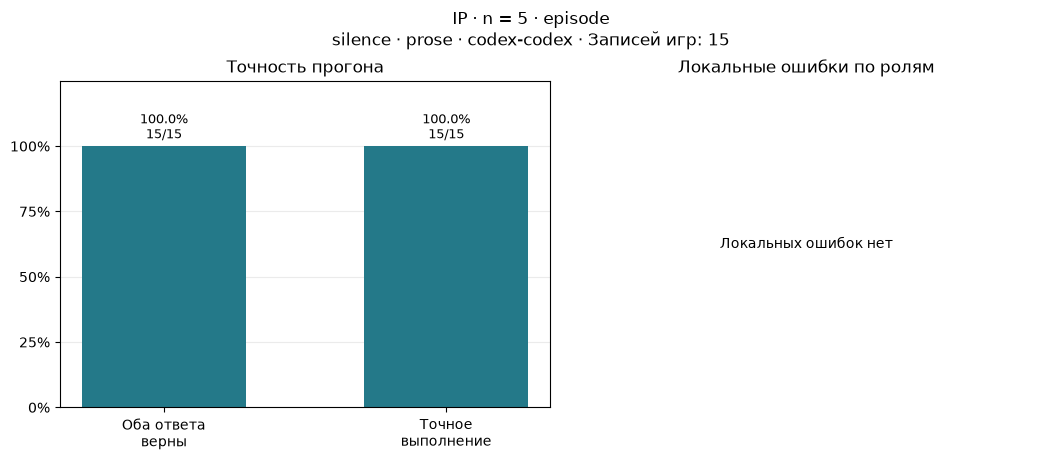

In [ ]:
from halfduplex.plotting import plot_results

plot_log_path = globals().get("log_path")
if plot_log_path is None:
    plot_log_path = max(
        (p for p in (PROJECT_ROOT / "results").glob("experiment4_*.jsonl") if "_analysis_" not in p.name),
        key=lambda p: p.stat().st_mtime_ns, default=None,
    )
print("Журнал для графика:", plot_log_path)
if plot_log_path is not None:
    plot_figure = plot_results(plot_log_path)
    # Для нового прогона сохраняем рядом с его журналом.
    if Path(plot_log_path).name == "journal.jsonl":
        plot_figure.savefig(Path(plot_log_path).with_name("plots.png"), dpi=180)
